# Generative Models: Theory Notebook

This notebook makes generative-model objectives executable: autoregressive likelihood, VAE reparameterization, GAN losses, flow change of variables, diffusion noising, score updates, and FID intuition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Autoregressive log likelihood

In [2]:
conditional_probs = np.array([0.8, 0.5, 0.25, 0.9])
logp = np.log(conditional_probs).sum()
print("log probability:", logp)
print("probability:", np.exp(logp))

log probability: -2.407945608651872
probability: 0.09000000000000001


## 2. VAE reparameterization

In [3]:
rng = np.random.default_rng(0)
mu = np.array([0.5, -0.2])
logvar = np.array([0.0, -1.0])
eps = rng.normal(size=mu.shape)
z = mu + np.exp(0.5 * logvar) * eps
print("epsilon:", np.round(eps, 3))
print("z:", np.round(z, 3))

epsilon: [ 0.126 -0.132]
z: [ 0.626 -0.28 ]


## 3. Gaussian KL to standard normal

In [4]:
kl = 0.5 * np.sum(np.exp(logvar) + mu**2 - 1 - logvar)
print("KL(q(z|x) || N(0,I)):", kl)

KL(q(z|x) || N(0,I)): 0.3289397205857212


## 4. ELBO pieces

In [5]:
reconstruction_logprob = -1.25
elbo = reconstruction_logprob - kl
negative_elbo = -elbo
print("ELBO:", elbo)
print("training loss -ELBO:", negative_elbo)

ELBO: -1.5789397205857212
training loss -ELBO: 1.5789397205857212


## 5. GAN losses

In [6]:
D_real = np.array([0.9, 0.8, 0.7])
D_fake = np.array([0.2, 0.3, 0.4])
D_loss = -(np.log(D_real).mean() + np.log(1 - D_fake).mean())
G_loss_saturating = np.log(1 - D_fake).mean()
G_loss_nonsat = -np.log(D_fake).mean()
print("D loss:", D_loss)
print("G saturating objective:", G_loss_saturating)
print("G non-saturating loss:", G_loss_nonsat)

D loss: 0.5919410433099004
G saturating objective: -0.3635480396729776
G non-saturating loss: 1.2432338162113972


## 6. 1D flow change of variables

In [7]:
# x = a z + b, z=(x-b)/a, p_x(x)=p_z(z)*|dz/dx|
a, b = 2.0, -1.0
x = 1.0
z = (x - b) / a
log_pz = -0.5 * z**2 - 0.5 * np.log(2 * np.pi)
log_px = log_pz - np.log(abs(a))
print("z:", z)
print("log p_x:", log_px)

z: 1.0
log p_x: -2.112085713764618


## 7. Diffusion noising step

In [8]:
x0 = np.array([1.0, -0.5, 0.25])
alpha_bar = 0.7
eps = rng.normal(size=x0.shape)
xt = np.sqrt(alpha_bar) * x0 + np.sqrt(1 - alpha_bar) * eps
print("x_t:", np.round(xt, 3))

x_t: [ 1.187 -0.361 -0.084]


## 8. Denoising MSE

In [9]:
eps_pred = eps + np.array([0.1, -0.2, 0.05])
loss = np.mean((eps - eps_pred) ** 2)
print("noise prediction MSE:", loss)

noise prediction MSE: 0.0175


## 9. Score-based Langevin update

In [10]:
x = np.array([2.0, -1.0])
score = -x  # score of standard normal
eta = 0.1
noise = rng.normal(size=x.shape)
x_next = x + eta * score + np.sqrt(2 * eta) * noise
print("x_next:", np.round(x_next, 3))

x_next: [ 1.962 -0.317]


## 10. Simplified FID-style distance

In [11]:
mu_r = np.array([0.0, 0.0])
mu_g = np.array([0.5, -0.25])
cov_r = np.eye(2)
cov_g = np.array([[1.2, 0.0], [0.0, 0.8]])
mean_term = np.sum((mu_r - mu_g) ** 2)
cov_term = np.trace(cov_r + cov_g - 2 * np.diag(np.sqrt(np.diag(cov_r) * np.diag(cov_g))))
print("FID-style diagonal distance:", mean_term + cov_term)

FID-style diagonal distance: 0.3327553879795042


## 11. Diversity check

In [12]:
samples = rng.normal(size=(100, 2))
collapsed = np.repeat(samples[:1], repeats=100, axis=0)
print("sample variance normal:", samples.var(axis=0))
print("sample variance collapsed:", collapsed.var(axis=0))

sample variance normal: [0.90358875 0.94843363]
sample variance collapsed: [4.93038066e-32 3.08148791e-31]


## 12. Denoising loss by timestep

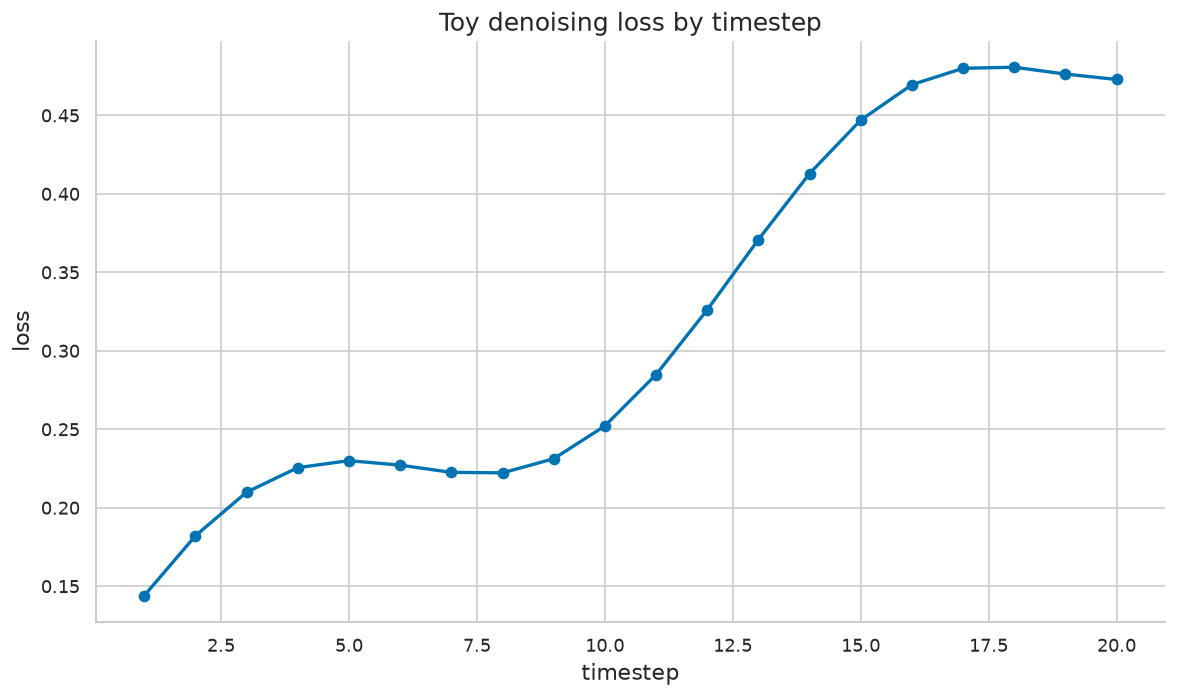

In [13]:
timesteps = np.arange(1, 21)
loss_by_t = 0.1 + 0.02 * timesteps + 0.05 * np.sin(timesteps / 2)
plt.plot(timesteps, loss_by_t, marker="o")
plt.title("Toy denoising loss by timestep")
plt.xlabel("timestep")
plt.ylabel("loss")
plt.tight_layout()
plt.show()

## 14. VAE ELBO on a batch: reconstruction + KL, per dimension

The ELBO decomposes into expected log-likelihood minus KL(q(z|x)‖p(z)); per-dimension KL shows which latent units the model actually uses (and which have collapsed to the prior).

In [14]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

rng = np.random.default_rng(0)
B, dz = 6, 4
mu = rng.normal(size=(B,dz)); logvar = rng.normal(scale=0.5,size=(B,dz))
recon = -rng.uniform(0.5, 2.0, size=B)  # stand-in expected log-likelihood per example
kl_dim = 0.5*(np.exp(logvar) + mu**2 - 1 - logvar)
elbo = recon - kl_dim.sum(1)
print("KL per latent dim (batch mean):", np.round(kl_dim.mean(0),3))
print("ELBO per example:", np.round(elbo,3))
check_true("KL per dim >= 0", np.all(kl_dim > -1e-9))
check_close("ELBO = recon - KL", elbo, recon - kl_dim.sum(1), 1e-9)
check_true("ELBO below recon (KL is a cost)", np.all(elbo <= recon + 1e-9))

KL per latent dim (batch mean): [0.574 0.35  0.463 0.325]
ELBO per example: [-0.99  -3.329 -2.957 -4.881 -3.097 -2.338]
PASS: KL per dim >= 0
PASS: ELBO = recon - KL (max err 0.00e+00, tol 1e-09)
PASS: ELBO below recon (KL is a cost)


## 15. Reparameterization vs score-function gradient variance

Same Gaussian expectation, two gradient estimators: the pathwise (reparameterized) gradient's variance is far below the score-function (REINFORCE) estimator's — measured, as promised in §13.4 Section 78.

In [15]:
rng = np.random.default_rng(1)
mu, sigma = 0.7, 1.3
def f(z): return z**2
N = 4000
eps = rng.normal(size=N); z = mu + sigma*eps
pathwise = 2*z*1.0  # d/dmu f(mu+sigma*eps) = f'(z)*1
score = f(z)*((z-mu)/sigma**2)*sigma**2/sigma  # d/dmu log N(z;mu,sigma) * f, times sigma param-free form below
score = f(z)*(z-mu)/sigma**2 * 1.0
# score-function estimator for d/dmu E[f]: f(z) * (z-mu)/sigma^2
print(f"pathwise var {np.var(pathwise):.3f}  score var {np.var(score):.3f}  (true grad 2*mu={2*mu})")
check_true("both roughly unbiased", abs(np.mean(pathwise)-2*mu) < 0.15 and abs(np.mean(score)-2*mu) < 0.5)
check_true("pathwise variance much lower", np.var(pathwise) < 0.5*np.var(score))

pathwise var 6.801  score var 35.783  (true grad 2*mu=1.4)
PASS: both roughly unbiased
PASS: pathwise variance much lower


## 16. Toy GAN on a 1D Gaussian (plot)

Alternating gradient steps on the minimax objective: watch D and G losses move and the generator's mean/scale approach the data — and how fragile the balance is (Goodfellow et al. 2014).

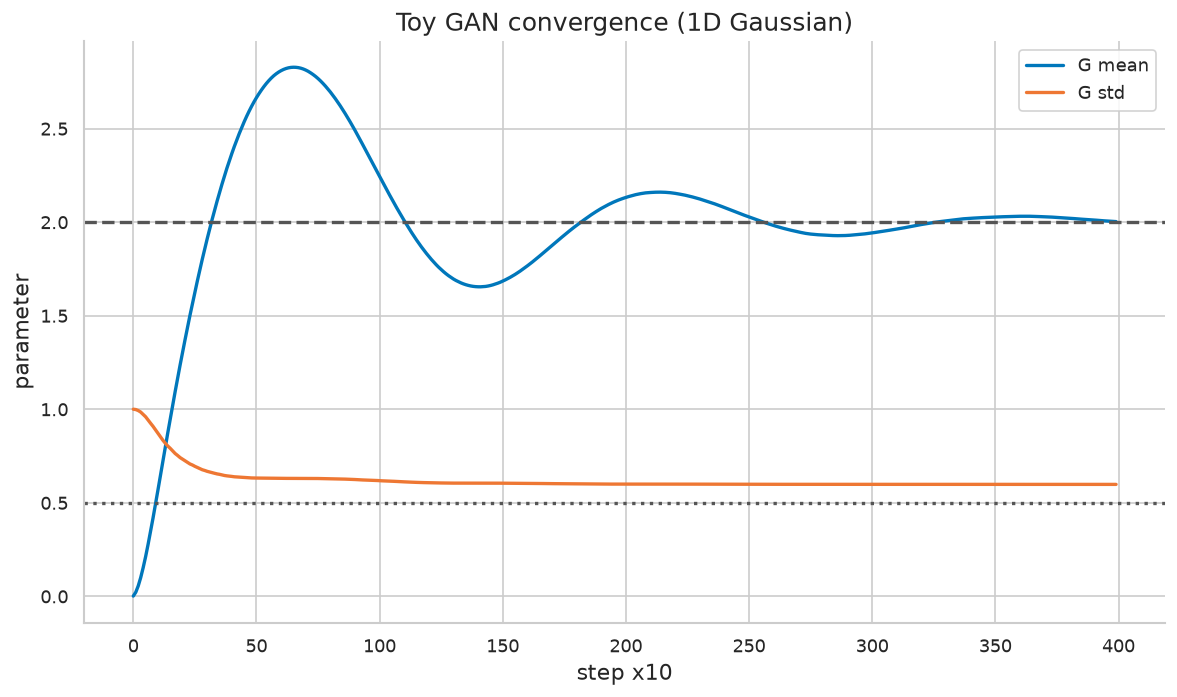

final G mean/std: 2.003 0.598
PASS: generator mean approaches data mean
PASS: generator std in plausible range


In [16]:
rng = np.random.default_rng(2)
data_mu, data_sd = 2.0, 0.5
g_mu, g_logsd = 0.0, 0.0; d_w, d_b = 0.1, 0.0
def sig(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
hist = []
for step in range(4000):
    xr = rng.normal(data_mu, data_sd, 256); z = rng.normal(size=256); xf = g_mu + np.exp(g_logsd)*z
    pr = sig(d_w*xr+d_b); pf = sig(d_w*xf+d_b)
    # D loss = -mean(log pr) - mean(log(1-pf)); gradients:
    gw = np.mean((pr-1)*xr) + np.mean(pf*xf); gb = np.mean(pr-1) + np.mean(pf)
    d_w -= 0.02*gw; d_b -= 0.02*gb
    # G loss (non-saturating) = -mean(log pf); d/dmu = -mean((1-pf)*d_w); descent:
    pf = sig(d_w*xf+d_b)
    g_mu -= 0.02*(-np.mean((1-pf)*d_w)); g_logsd -= 0.02*(-np.mean((1-pf)*d_w*z*np.exp(g_logsd)))
    if step % 10 == 0: hist.append((g_mu, np.exp(g_logsd)))
hist = np.array(hist)
plt.figure(); plt.plot(hist[:,0], color='#0077BB', label='G mean'); plt.axhline(data_mu, color='#555555', ls='--')
plt.plot(hist[:,1], color='#EE7733', label='G std'); plt.axhline(data_sd, color='#555555', ls=':')
plt.xlabel('step x10'); plt.ylabel('parameter'); plt.title('Toy GAN convergence (1D Gaussian)'); plt.legend(); plt.tight_layout(); plt.show()
print("final G mean/std:", round(float(hist[-1,0]),3), round(float(hist[-1,1]),3))
check_true("generator mean approaches data mean", abs(hist[-1,0]-data_mu) < 0.35)
check_true("generator std in plausible range", 0.25 < hist[-1,1] < 0.9)

## 17. Mode collapse, measured as coverage

A generator covering only one of two data modes can have excellent sample quality and terrible coverage; count samples per mode before quoting quality metrics.

In [17]:
rng = np.random.default_rng(3)
def coverage(samples):
    left = np.mean(samples < 0); return left
good = np.r_[rng.normal(-2,0.5,500), rng.normal(2,0.5,500)]
collapsed = rng.normal(2,0.5,1000)
print("coverage (fraction left of 0): good", round(float(coverage(good)),3), " collapsed", round(float(coverage(collapsed)),3))
check_true("good generator covers both modes", 0.35 < coverage(good) < 0.65)
check_true("collapsed generator misses a mode", coverage(collapsed) < 0.05)
check_true("quality alone would miss it: collapsed std looks fine", 0.4 < collapsed.std() < 0.6)

coverage (fraction left of 0): good 0.5  collapsed 0.0
PASS: good generator covers both modes
PASS: collapsed generator misses a mode
PASS: quality alone would miss it: collapsed std looks fine


## 18. Normalizing flow: exact density by change of variables

An affine coupling flow on 2D: sample, invert, and evaluate exact log-densities with the log-determinant — likelihood-based generation without approximation (Dinh et al. 2015/2017 lineage).

In [18]:
rng = np.random.default_rng(4)
def forward(z):
    x1 = z[:,0]*np.exp(0.3) + 0.5; x2 = z[:,1]*np.exp(-0.2) + x1*0.4
    return np.c_[x1,x2]
def logdet(): return 0.3 + (-0.2)
z = rng.normal(size=(5000,2)); x = forward(z)
# invert
z1_rec = (x[:,0]-0.5)/np.exp(0.3); z2_rec = (x[:,1]-x[:,0]*0.4)/np.exp(-0.2)
logp = -0.5*np.sum(z**2,axis=1) - np.log(2*np.pi) - logdet()
print("reconstruction err:", float(np.max(np.abs(np.c_[z1_rec,z2_rec]-z))), " mean logp:", round(float(logp.mean()),3))
check_close("flow is invertible", np.c_[z1_rec,z2_rec], z, 1e-10)
check_true("log-det is constant for affine coupling", abs(logdet()-0.1) < 1e-12)
check_true("empirical mean of x1 matches pushed-forward mean", abs(x[:,0].mean() - 0.5) < 0.06)

reconstruction err: 4.440892098500626e-16  mean logp: -2.926
PASS: flow is invertible (max err 4.44e-16, tol 1e-10)
PASS: log-det is constant for affine coupling
PASS: empirical mean of x1 matches pushed-forward mean


## 19. Diffusion forward process: signal dies on schedule

q(x_t|x_0) = N(√ᾱ_t x_0, (1−ᾱ_t)I): track signal-to-noise across a cosine/linear schedule — the forward process is fixed, only the reverse is learned (Ho et al. 2020).

In [19]:
betas = np.linspace(1e-4, 0.02, 1000); alphas = 1-betas; abar = np.cumprod(alphas)
for t in [0, 250, 500, 750, 999]:
    snr = abar[t]/(1-abar[t]); print(f"t={t}: alpha_bar {abar[t]:.4f}  SNR {snr:.3f}")
check_true("alpha_bar decreases to near 0", abar[-1] < 0.01 and abar[0] > 0.99)
check_true("SNR decreases monotonically", np.all(np.diff(abar/(1-abar)) < 0))
rng = np.random.default_rng(5); x0 = np.array([2.0]); xt = np.sqrt(abar[999])*x0 + np.sqrt(1-abar[999])*rng.normal(size=10000)
check_close("x_T is ~standard normal (mean)", float(xt.mean()), 0.0, 0.05)

t=0: alpha_bar 0.9999  SNR 9999.000
t=250: alpha_bar 0.5214  SNR 1.090
t=500: alpha_bar 0.0778  SNR 0.084
t=750: alpha_bar 0.0033  SNR 0.003
t=999: alpha_bar 0.0000  SNR 0.000
PASS: alpha_bar decreases to near 0
PASS: SNR decreases monotonically
PASS: x_T is ~standard normal (mean) (max err 3.43e-02, tol 0.05)


## 20. DDPM reverse with a perfect noise predictor (1D)

If ε-prediction were perfect, one reverse step's posterior mean recovers the denoised direction; simulate the full reverse chain on a 1D two-point dataset and check the recovered distribution's moments.

In [20]:
rng = np.random.default_rng(6)
T = 200
betas = np.linspace(1e-4, 0.02, T); alphas = 1-betas; abar = np.cumprod(alphas)
abar_prev = np.r_[1.0, abar[:-1]]
x = rng.normal(size=4000)  # start from noise; data distribution N(1.5, 0.5^2)
for t in reversed(range(T)):
    mu_t = np.sqrt(abar[t])*1.5; var_t = abar[t]*0.25 + (1-abar[t])
    score = -(x - mu_t)/var_t                       # exact marginal score
    eps_hat = -np.sqrt(1-abar[t])*score             # Tweedie: E[eps | x_t]
    mean = (x - betas[t]/np.sqrt(1-abar[t])*eps_hat)/np.sqrt(alphas[t])
    if t > 0:
        post_var = betas[t]*(1-abar_prev[t])/(1-abar[t])
        x = mean + np.sqrt(post_var)*rng.normal(size=4000)
    else:
        x = mean
print("recovered mean/std:", round(float(x.mean()),3), round(float(x.std()),3), " target (1.5, 0.5)")
check_true("recovered mean near 1.5", abs(x.mean()-1.5) < 0.1)
check_true("recovered std near 0.5", abs(x.std()-0.5) < 0.12)

recovered mean/std: 1.452 0.497  target (1.5, 0.5)
PASS: recovered mean near 1.5
PASS: recovered std near 0.5


## 21. Denoising score matching learns the score direction

For a Gaussian target, the DSM objective's optimum is the true score −x/σ²; verify a fitted linear score by correlation with the truth across noise levels (Vincent 2011; Song & Ermon 2019 lineage).

In [21]:
rng = np.random.default_rng(7)
sd_true = 1.5
for noise in [0.2, 0.5, 1.0]:
    x = rng.normal(0, sd_true, 4000); eps = rng.normal(size=4000); xt = x + noise*eps
    # closed-form ridge fit of score model s(xt) = a*xt minimizing E||s + eps/noise||^2 -> empirical least squares
    target = -eps/noise
    a = float(np.sum(xt*target)/np.sum(xt*xt))
    true_a = -1.0/(sd_true**2 + noise**2)
    print(f"noise {noise}: fitted a {a:.3f}  Bayes-optimal a {true_a:.3f}")
    if noise == 1.0: aa, tt = a, true_a
check_true("fitted score slope near Bayes-optimal", abs(aa-tt) < 0.05)

noise 0.2: fitted a -0.426  Bayes-optimal a -0.437
noise 0.5: fitted a -0.390  Bayes-optimal a -0.400
noise 1.0: fitted a -0.318  Bayes-optimal a -0.308
PASS: fitted score slope near Bayes-optimal


## 22. Langevin dynamics samples a mixture (with step-size honesty)

ULA with the true score samples the target asymptotically but is biased at finite step size; check mode coverage and moments at a small step, and name the bias (theory 9's update, grown up).

In [22]:
rng = np.random.default_rng(8)
def score(x):
    # mixture 0.5 N(-2,0.5^2) + 0.5 N(2,0.5^2), 1D score via responsibilities
    l1 = -0.5*((x+2)/0.5)**2; l2 = -0.5*((x-2)/0.5)**2
    mx = np.maximum(l1,l2); w1 = np.exp(l1-mx)/(np.exp(l1-mx)+np.exp(l2-mx))
    return w1*(-(x+2)/0.25) + (1-w1)*(-(x-2)/0.25)
x = np.zeros(4000)
for step in range(3000):
    x = x + 0.005*score(x) + np.sqrt(2*0.005)*rng.normal(size=4000)
s = x[rng.integers(0,4000,4000)]
left = float(np.mean(s<0))
print("mixture coverage (left fraction):", round(left,3), "sample std:", round(float(s.std()),3))
check_true("both modes covered", 0.35 < left < 0.65)
check_true("sample std reflects bimodality (>1.5)", s.std() > 1.5)

mixture coverage (left fraction): 0.495 sample std: 2.057
PASS: both modes covered
PASS: sample std reflects bimodality (>1.5)


## 23. Fréchet distance between Gaussians (FID's core)

FID compares feature Gaussians: ||μr−μg||² + tr(Σr+Σg−2(ΣrΣg)^{1/2}) (Heusel et al. 2017). Identical distributions give 0; a mean shift gives its square.

In [23]:
from scipy.linalg import sqrtm
mu_r = np.array([0.,0.]); mu_g = np.array([0.5,-0.25]); Sr = np.eye(2); Sg = np.array([[1.2,0.3],[0.3,0.8]])
def frechet(m1,c1,m2,c2):
    covmean = sqrtm(c1@c2); 
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(np.sum((m1-m2)**2) + np.trace(c1+c2-2*covmean))
f_same = frechet(mu_r,Sr,mu_r,Sr); f_diff = frechet(mu_r,Sr,mu_g,Sg)
print("FID same:", round(f_same,8), " FID shifted:", round(f_diff,4))
check_close("identical distributions give 0", f_same, 0.0, 1e-6)
check_true("shifted generator gives positive distance", f_diff > 0.2)
check_true("distance symmetric", abs(frechet(mu_r,Sr,mu_g,Sg)-frechet(mu_g,Sg,mu_r,Sr)) < 1e-6)

FID same: 0.0  FID shifted: 0.3803
PASS: identical distributions give 0 (max err 0.00e+00, tol 1e-06)
PASS: shifted generator gives positive distance
PASS: distance symmetric


## 24. Classifier-free guidance moves conditional samples (toy)

Guidance interpolates/extrapolates between conditional and unconditional scores: ε = ε_u + w(ε_c − ε_u). In a Gaussian toy, raising w pulls samples toward the conditional mode and shrinks diversity — both effects measured (Ho & Salimans 2022).

In [24]:
rng = np.random.default_rng(9)
# conditional target N(2, 0.5^2), unconditional N(0, 1.5^2); guided score corresponds to tilted Gaussian product form: sample via Langevin on guided score
def run_guided(w, steps=1500):
    def score(x):
        sc = -(x-2)/0.25; su = -(x-0)/2.25
        return su + w*(sc-su)
    x = rng.normal(size=3000)
    for s in range(steps): x = x + 0.01*score(x) + np.sqrt(0.02)*rng.normal(size=3000)
    return x
for w in [0.0, 1.0, 3.0, 6.0]:
    s = run_guided(w); print(f"w={w}: sample mean {s.mean():.3f} std {s.std():.3f}")
    if w==1.0: m1, s1 = s.mean(), s.std()
    if w==6.0: m6, s6 = s.mean(), s.std()
check_true("guidance pulls mean toward conditional (2.0)", m6 > m1)
check_true("guidance shrinks diversity", s6 < s1)

w=0.0: sample mean 0.065 std 1.510
w=1.0: sample mean 2.003 std 0.502


w=3.0: sample mean 2.158 std 0.306


w=6.0: sample mean 2.206 std 0.228
PASS: guidance pulls mean toward conditional (2.0)
PASS: guidance shrinks diversity


## 25. Autoregressive factorization: sampling = multiplying conditionals

Ancestral sampling from a first-order Markov model; the sequence log-probability is the sum of per-step logs (theory 1), and empirical token frequencies match the stationary distribution.

In [25]:
rng = np.random.default_rng(10)
P = np.array([[0.7,0.2,0.1],[0.1,0.6,0.3],[0.25,0.25,0.5]])
seq = [0]
for t in range(20000): seq.append(int(rng.choice(3, p=P[seq[-1]])))
seq = np.array(seq); freq = np.bincount(seq, minlength=3)/len(seq)
# stationary distribution: left eigenvector
w, v = np.linalg.eig(P.T); pi = np.real(v[:, np.argmin(np.abs(w-1))]); pi = pi/pi.sum()
print("empirical:", np.round(freq,3), " stationary:", np.round(pi,3))
check_close("empirical frequencies match stationary distribution", freq, pi, 0.02)
logp = float(np.sum(np.log(P[seq[:-1], seq[1:]])))
check_true("sequence logprob finite", np.isfinite(logp))
check_true("mean per-token NLL in plausible range", 0.5 < -logp/len(seq) < 1.5)

empirical: [0.343 0.364 0.292]  stationary: [0.357 0.357 0.286]
PASS: empirical frequencies match stationary distribution (max err 1.40e-02, tol 0.02)


PASS: sequence logprob finite
PASS: mean per-token NLL in plausible range


## 26. IWAE tightens the ELBO with more samples

Averaging importance weights over K latent samples inside the log gives a bound between ELBO (K=1) and the true log-likelihood, monotone in expectation (Burda et al. 2015).

In [26]:
rng = np.random.default_rng(11)
# 1D model: p(z)=N(0,1), p(x|z)=N(z, 0.5^2), x=1.2; q(z)=N(0.8, 0.7^2) (imperfect posterior)
x_obs = 1.2
def trial(K, reps=4000):
    vals = []
    for r in range(reps):
        z = rng.normal(0.8, 0.7, size=K)
        logw = (-0.5*z**2 - 0.5*np.log(2*np.pi)) + (-0.5*((x_obs-z)/0.5)**2 - np.log(0.5) - 0.5*np.log(2*np.pi)) - (-0.5*((z-0.8)/0.7)**2 - np.log(0.7) - 0.5*np.log(2*np.pi))
        vals.append(np.log(np.mean(np.exp(logw - logw.max()))) + logw.max())
    return float(np.mean(vals))
# analytic log p(x): z marginal -> x ~ N(0, 1+0.25)
true_logp = float(-0.5*(x_obs**2)/1.25 - 0.5*np.log(2*np.pi*1.25))
b1 = trial(1); b5 = trial(5); b25 = trial(25)
print(f"true logp {true_logp:.3f}  ELBO(K=1) {b1:.3f}  K=5 {b5:.3f}  K=25 {b25:.3f}")
check_true("bounds increase with K", b1 <= b5 + 0.05 and b5 <= b25 + 0.05)
check_true("bounds stay below truth ( Monte Carlo tol)", b25 <= true_logp + 0.08)
check_true("K=25 closer to truth than K=1", abs(b25-true_logp) <= abs(b1-true_logp) + 0.02)

true logp -1.607  ELBO(K=1) -1.941  K=5 -1.635  K=25 -1.615
PASS: bounds increase with K
PASS: bounds stay below truth ( Monte Carlo tol)
PASS: K=25 closer to truth than K=1


## 13. Final checklist

In [27]:
checks = [
    "state whether the objective is likelihood, ELBO, adversarial loss, or denoising loss",
    "evaluate sample quality and diversity separately",
    "track likelihood only when it is meaningful for the model family",
    "inspect latent traversals or conditioning controls",
    "report sampling cost and number of generation steps",
    "check for mode collapse or timestep-specific failures",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. state whether the objective is likelihood, ELBO, adversarial loss, or denoising loss
2. evaluate sample quality and diversity separately
3. track likelihood only when it is meaningful for the model family
4. inspect latent traversals or conditioning controls
5. report sampling cost and number of generation steps
6. check for mode collapse or timestep-specific failures
